# Industry Project: "Find Similar Products from a Photo" (Production-Style Visual Search)

> **Who is this notebook for?** Someone who has never built a search engine for images.
> You do **not** need the math from the other notebooks. Every step is explained in plain English, and almost every line of code has a comment.
> Everything runs on a laptop CPU. The only download is a small pretrained network (MobileNetV3-Small, ~10 MB); the product images are generated inside the notebook.

---

### How this notebook is different from the other notebooks

| `02_image_classification.ipynb`, `projects/03_image_similarity.py`, `22_ML_System_Design/05_vector_databases.ipynb` | This notebook |
|---|---|
| Explain CNNs, embeddings and vector indexes (HNSW, IVF) **in theory** or as a script | Builds a **complete visual search feature** for an online shop |
| Measure accuracy of a classifier | Measures **retrieval quality** (recall@k, mAP) with a known ground truth |
| One index type at a time | **Exact vs approximate** search side by side: recall vs speed vs memory |
| No life-cycle | Validation, baseline, near-duplicate detection, **adding/removing products**, a search service, saving, latency, tests |

---

### The business problem

You work for an online marketplace. Shoppers often see a product they like (on the street, on social media) but don't know what it is called. The product team wants a **"search by photo"** button: the shopper takes a picture and the app shows the **10 most similar products** from the catalog.

Constraints and goals:
- The catalog changes every day: **new products must be searchable within minutes**, discontinued ones must disappear.
- Sellers sometimes upload **the same product twice** (duplicate listings). These should be **detected at upload time** and merged in the results.
- The search must answer in **< 100 ms** on a CPU server and fit in memory even when the catalog grows to millions of items.
- **Success metric:** the product the shopper photographed appears in the top 10 results (**recall@10**). The app shows a grid of 10 items, so position 1 vs position 7 matters less than being on the screen at all.

---

### How visual search works (the big picture)

```
OFFLINE (every time the catalog changes)                 ONLINE (every shopper request, < 100 ms)
 catalog image -> preprocess -> CNN -> embedding ─┐        photo -> validate -> preprocess -> CNN -> embedding
                                                  v                                                   |
                                    vector index (FAISS) <────────── nearest-neighbour search <───────┘
                                                                              |
                                                               top-10 product IDs -> product page
```

An **embedding** is a list of numbers (here 576) that summarises what an image looks like. Similar-looking images get embeddings that point in a similar direction, so "find similar products" becomes "find the nearest vectors", which a vector index like **FAISS** does very fast.

### Table of Contents
1. Setup: imports and one central config
2. Build the catalog (simulated product photos)
3. Simulate shopper photos (the queries) and the ground truth
4. Validate and normalise incoming images
5. Baseline first: colour histograms
6. CNN embeddings with correct preprocessing
7. Exact search with FAISS and retrieval metrics
8. A cheap improvement: multi-view catalog embeddings
9. Look at the results and the failures
10. Near-duplicate detection (duplicate listings)
11. Scaling up: exact vs approximate indexes (Flat, IVF, HNSW, IVF-PQ)
12. Adding and removing products
13. The search service
14. Save and reload the index
15. Latency and memory summary
16. Automated tests
17. Summary, exercises and resources

---
## 1. Setup: imports and one central config

All settings live in one `Config`. We fix seeds for reproducibility and limit the number of CPU threads (this notebook may run on a shared machine; on a dedicated server you would use all cores).

In [1]:
# ---- Standard library ----
import json                      # to save index metadata
import logging                   # status messages with timestamps
import tempfile                  # temporary folder for the saved index (we never write into the repo)
import time                      # timing
import warnings
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from pathlib import Path

# ---- Third-party libraries ----
import cv2                       # OpenCV: drawing the product images, image conversions
import faiss                     # Facebook AI Similarity Search: fast vector indexes
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("visual_search")


@dataclass(frozen=True)
class Config:
    seed: int = 42
    n_products: int = 400            # products in our (small) catalog
    n_duplicate_listings: int = 40   # products that a second seller uploaded again
    n_new_products: int = 40         # products added later (Section 12)
    image_size: int = 224            # size of the rendered studio photos
    top_k: int = 10                  # the app shows a grid of 10 results
    n_filler_vectors: int = 30_000   # simulated extra catalog items for the scaling test
    batch_size: int = 64             # images per forward pass when embedding
    num_threads: int = 2             # CPU threads for PyTorch and FAISS (shared machine)
    latency_budget_ms: float = 100.0


CFG = Config()
np.random.seed(CFG.seed)
torch.manual_seed(CFG.seed)
torch.set_num_threads(CFG.num_threads)
faiss.omp_set_num_threads(CFG.num_threads)
log.info("torch %s | torchvision %s | faiss %s", torch.__version__, torchvision.__version__, faiss.__version__)
print(CFG)

2026-10-21 17:38:49,606 | INFO | torch 2.12.1+cpu | torchvision 0.27.1+cpu | faiss 1.14.3


Config(seed=42, n_products=400, n_duplicate_listings=40, n_new_products=40, image_size=224, top_k=10, n_filler_vectors=30000, batch_size=64, num_threads=2, latency_budget_ms=100.0)


---
## 2. Build the catalog (simulated product photos)

A real catalog lives in a database plus an object store (S3) for the images:

```python
# Real-life version (not run here):
# products = pd.read_sql("SELECT sku, title, category, image_url FROM products WHERE active", engine)
# images = [load_image_from_s3(url) for url in products.image_url]
```

To stay offline we **draw** product photos: 8 categories (t-shirts, mugs, bottles, sneakers, backpacks, caps, watches, lamps), 15 colours with small variations, 4 patterns, optional two-letter logos and random proportions. The studio photos are clean: product centred on a white background, like real catalog pictures.

This catalog is **deliberately confusing**: with 400 products and only 8 × 15 × 4 basic combinations, there are many look-alikes (e.g. several red striped t-shirts that differ only in logo or proportions). That is realistic: fashion catalogs are full of near-identical items.

We also add **duplicate listings**: 40 products re-uploaded by a second seller with a slightly tighter crop, different brightness and JPEG quality, sometimes with a "SALE" banner.

In [2]:
COLORS = {"black": (30, 30, 30), "white": (235, 235, 235), "grey": (128, 128, 128), "red": (200, 30, 40),
          "navy": (25, 40, 110), "blue": (40, 110, 210), "green": (40, 140, 60), "olive": (110, 120, 50),
          "yellow": (235, 200, 40), "orange": (240, 120, 30), "pink": (235, 130, 170), "purple": (120, 60, 160),
          "brown": (120, 75, 40), "beige": (215, 195, 160), "teal": (30, 140, 140)}
CATEGORIES = ["t-shirt", "mug", "bottle", "sneaker", "backpack", "cap", "watch", "lamp"]
PATTERNS = ["solid", "stripes", "dots", "checks"]
S = CFG.image_size


def product_mask(category: str, shape: dict) -> np.ndarray:
    """Silhouette of the product (255 = product, 0 = background), drawn with OpenCV primitives."""
    m = np.zeros((S, S), np.uint8)
    w, h = 0.8 + 0.3 * shape["w"], 0.8 + 0.3 * shape["h"]          # product-specific proportions
    pt = lambda x, y: (int(S / 2 + (x - .5) * S * w), int(S / 2 + (y - .5) * S * h))   # relative -> pixels
    axes = lambda a, b: (int(S * a * w), int(S * b * h))
    if category == "t-shirt":
        poly = [pt(.3, .2), pt(.42, .17), pt(.5, .22), pt(.58, .17), pt(.7, .2), pt(.88, .38), pt(.78, .45),
                pt(.7, .38), pt(.7, .82), pt(.3, .82), pt(.3, .38), pt(.22, .45), pt(.12, .38)]
        cv2.fillPoly(m, [np.array(poly, np.int32)], 255)
    elif category == "mug":
        cv2.rectangle(m, pt(.28, .25), pt(.65, .8), 255, -1)
        cv2.ellipse(m, pt(.66, .5), axes(.12, .14), 0, -90, 90, 255, int(S * .04))
    elif category == "bottle":
        cv2.rectangle(m, pt(.36, .35), pt(.64, .88), 255, -1)
        cv2.fillPoly(m, [np.array([pt(.36, .36), pt(.45, .22), pt(.55, .22), pt(.64, .36)], np.int32)], 255)
        cv2.rectangle(m, pt(.44, .1), pt(.56, .23), 255, -1)
    elif category == "sneaker":
        cv2.ellipse(m, pt(.5, .62), axes(.38, .13), 0, 0, 360, 255, -1)
        cv2.fillPoly(m, [np.array([pt(.15, .62), pt(.25, .38), pt(.5, .35), pt(.62, .5), pt(.85, .55), pt(.88, .65)], np.int32)], 255)
    elif category == "backpack":
        cv2.rectangle(m, pt(.25, .22), pt(.75, .88), 255, -1)
        cv2.ellipse(m, pt(.5, .22), axes(.25, .12), 0, 180, 360, 255, -1)
        cv2.ellipse(m, pt(.5, .15), axes(.08, .06), 0, 180, 360, 255, int(S * .03))
    elif category == "cap":
        cv2.ellipse(m, pt(.45, .6), axes(.28, .25), 0, 180, 360, 255, -1)
        cv2.ellipse(m, pt(.7, .6), axes(.22, .06), 0, 0, 360, 255, -1)
    elif category == "watch":
        cv2.rectangle(m, pt(.42, .08), pt(.58, .92), 255, -1)
        cv2.circle(m, pt(.5, .5), int(S * .18 * min(w, h)), 255, -1)
    else:  # lamp
        cv2.fillPoly(m, [np.array([pt(.3, .45), pt(.4, .15), pt(.6, .15), pt(.7, .45)], np.int32)], 255)
        cv2.rectangle(m, pt(.48, .45), pt(.52, .82), 255, -1)
        cv2.ellipse(m, pt(.5, .85), axes(.15, .04), 0, 0, 360, 255, -1)
    return m


def render_product(p: dict, background=(250, 250, 250)) -> np.ndarray:
    """Studio photo of product p: coloured, patterned silhouette with simple shading and an optional logo."""
    img = np.zeros((S, S, 3), np.uint8); img[:] = background
    mask = product_mask(p["category"], p["shape"])
    body = np.zeros_like(img); body[:] = p["rgb_main"]
    step = int(8 + 14 * p["shape"]["pattern_scale"])                 # pattern size differs per product
    on = np.zeros((S, S), np.uint8)
    if p["pattern"] == "stripes":
        for y in range(0, S, step * 2): on[y:y + step // 2 + 2] = 255
    elif p["pattern"] == "dots":
        for y in range(step // 2, S, step):
            for x in range(step // 2, S, step): cv2.circle(on, (x, y), max(2, step // 4), 255, -1)
    elif p["pattern"] == "checks":
        for y in range(0, S, step):
            for x in range(0, S, step):
                if (x // step + y // step) % 2 == 0: on[y:y + step, x:x + step] = 255
    body[on > 0] = p["rgb_second"]
    body = np.clip(body * np.linspace(1.08, 0.85, S)[:, None, None], 0, 255).astype(np.uint8)   # top-down shading
    img[mask > 0] = body[mask > 0]
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.polylines(img, contours, True, (40, 40, 40), 1, cv2.LINE_AA)                          # outline
    if p["logo"]:
        ys, xs = np.nonzero(mask)
        cv2.putText(img, p["logo"], (int(xs.mean()) - 14, int(ys.mean()) + 8), cv2.FONT_HERSHEY_SIMPLEX,
                    0.8, p["rgb_logo"], 2, cv2.LINE_AA)
    return img


def make_products(n: int, rng, first_id: int = 10000) -> pd.DataFrame:
    """Random product attributes (what the catalog database would contain)."""
    rows, names = [], list(COLORS)
    jitter = lambda c: tuple(int(np.clip(v + rng.normal(0, 12), 0, 255)) for v in COLORS[c])
    for i in range(n):
        c1, c2, c3 = rng.choice(names, 3, replace=False)
        rows.append({"sku": first_id + i, "category": str(rng.choice(CATEGORIES)), "color": str(c1),
                     "pattern": str(rng.choice(PATTERNS, p=[0.4, 0.2, 0.2, 0.2])),
                     "logo": "".join(rng.choice(list("ABCDEFGHKMNPRSTXZ"), 2)) if rng.random() < 0.75 else "",
                     "rgb_main": jitter(c1), "rgb_second": jitter(c2), "rgb_logo": jitter(c3),
                     "shape": {"w": rng.random(), "h": rng.random(), "pattern_scale": rng.random()}})
    df = pd.DataFrame(rows)
    df["title"] = df["color"] + " " + df["pattern"] + " " + df["category"]
    return df


def reupload(img: np.ndarray, rng) -> np.ndarray:
    """A second seller's copy of the same photo: new crop, brightness, JPEG quality, maybe a 'SALE' banner."""
    crop = rng.uniform(0.96, 1.0)
    c = int(S * crop); x0 = y0 = (S - c) // 2                       # centred crop (a few % removed)
    out = cv2.resize(img[y0:y0 + c, x0:x0 + c], (S, S), interpolation=cv2.INTER_AREA)
    out = np.clip(out.astype(np.float32) * rng.uniform(0.9, 1.1), 0, 255).astype(np.uint8)
    if rng.random() < 0.4:
        cv2.putText(out, "SALE", (8, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (220, 0, 0), 2, cv2.LINE_AA)
    ok, enc = cv2.imencode(".jpg", out, [cv2.IMWRITE_JPEG_QUALITY, int(rng.integers(60, 90))])
    return cv2.imdecode(enc, cv2.IMREAD_UNCHANGED)


rng = np.random.default_rng(CFG.seed)
products = make_products(CFG.n_products, rng)
studio_images = [render_product(p) for p in products.to_dict("records")]

# Duplicate listings: same product, new SKU, slightly edited photo
dup_src = rng.choice(CFG.n_products, CFG.n_duplicate_listings, replace=False)
duplicates = products.iloc[dup_src].copy()
duplicates["duplicate_of"] = duplicates["sku"]
duplicates["sku"] = np.arange(90000, 90000 + len(duplicates))           # the second seller's SKUs
catalog = pd.concat([products.assign(duplicate_of=-1), duplicates], ignore_index=True)
catalog_images = studio_images + [reupload(studio_images[i], rng) for i in dup_src]
catalog["product_group"] = np.where(catalog.duplicate_of >= 0, catalog.duplicate_of, catalog.sku)   # same real product
print(f"Catalog: {len(catalog)} listings for {catalog.product_group.nunique()} real products")
catalog[["sku", "title", "logo", "duplicate_of", "product_group"]].head()

Catalog: 440 listings for 400 real products


,sku,title,logo,duplicate_of,product_group
0,10000,orange dots watch,KZ,-1,10000
1,10001,navy solid watch,,-1,10001
2,10002,green solid sneaker,XH,-1,10002
3,10003,red solid backpack,HP,-1,10003
4,10004,brown solid bottle,CM,-1,10004


---
## 3. Simulate shopper photos (the queries) and the ground truth

To measure search quality we need **queries with known answers**. In a real company you get them from:
- **logs**: the shopper searched with a photo and then bought / clicked product X,
- **manual labelling** of a few hundred queries (the "golden set"),
- or, to start, **augmented copies** of catalog images, exactly what we do here.

A shopper's photo is very different from a studio photo: cluttered table or floor as background, the product smaller and rotated, a perspective tilt, different light and colour temperature, motion blur and strong JPEG compression. Photos also come in **different resolutions**.

> ⚠️ Honest caveat: our queries are generated by a program, so their "style" is narrower than real shopper photos. Real-world recall is usually lower than on simulated queries. Always confirm with a labelled set of real queries.

2026-10-21 17:39:00,410 | INFO | Created 400 shopper photos in 8.2s


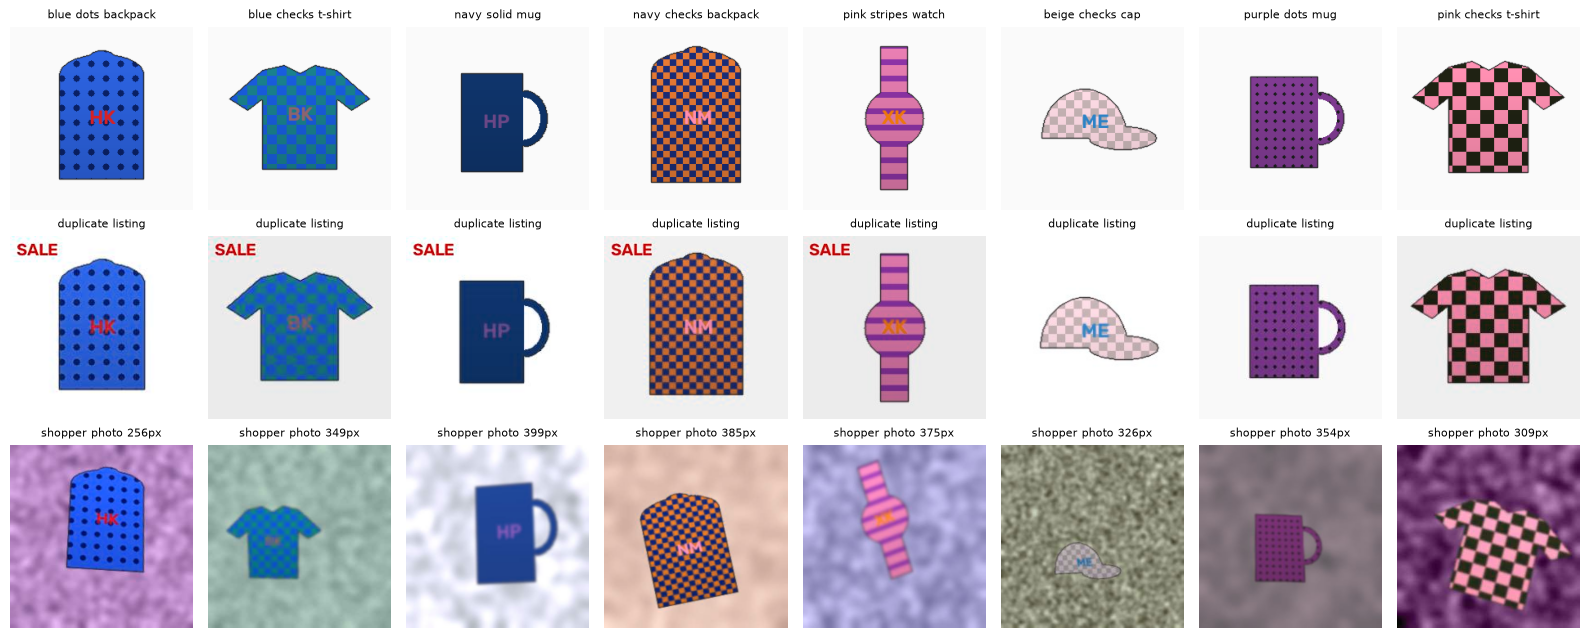

In [3]:
def random_background(rng) -> np.ndarray:
    """A mostly neutral, softly textured surface (table, floor, fabric)."""
    base = rng.uniform(70, 220) + rng.uniform(-35, 35, 3)
    texture = cv2.GaussianBlur(rng.normal(0, 1, (S, S)).astype(np.float32), (0, 0), rng.uniform(2, 10))
    texture /= texture.std() + 1e-6
    return np.clip(base[None, None, :] + texture[..., None] * rng.uniform(5, 25), 0, 255).astype(np.uint8)


def shopper_photo(p: dict, rng) -> np.ndarray:
    """What a shopper's phone photo of product p might look like."""
    obj = render_product(p, background=(0, 0, 0))
    mask = (product_mask(p["category"], p["shape"]) > 0).astype(np.float32)
    M = cv2.getRotationMatrix2D((S / 2, S / 2), rng.uniform(-20, 20), rng.uniform(0.6, 1.0))   # angle + distance
    M[:, 2] += rng.uniform(-0.12, 0.12, 2) * S                                                     # off-centre
    obj, mask = cv2.warpAffine(obj, M, (S, S)), cv2.warpAffine(mask, M, (S, S))
    corners = np.float32([[0, 0], [S, 0], [S, S], [0, S]])
    tilt = cv2.getPerspectiveTransform(corners, corners + rng.uniform(-0.07, 0.07, (4, 2)).astype(np.float32) * S)
    obj, mask = cv2.warpPerspective(obj, tilt, (S, S)), cv2.warpPerspective(mask, tilt, (S, S))
    img = random_background(rng) * (1 - mask[..., None]) + obj * mask[..., None]   # paste onto the background
    img = img * rng.uniform(0.7, 1.25) + rng.uniform(-20, 20)                       # exposure
    img = img * (1 + rng.normal(0, 0.06, 3))[None, None, :]                           # colour temperature
    img = np.clip(img, 0, 255).astype(np.uint8)
    if rng.random() < 0.5:
        img = cv2.GaussianBlur(img, (0, 0), rng.uniform(0.5, 1.8))                    # hand shake / focus
    side = int(rng.integers(160, 400))                                                 # phones send any size
    img = cv2.resize(img, (side, side), interpolation=cv2.INTER_LINEAR)
    ok, enc = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, int(rng.integers(35, 85))])
    return cv2.imdecode(enc, cv2.IMREAD_UNCHANGED)


t0 = time.time()
query_images = [shopper_photo(p, rng) for p in products.to_dict("records")]      # one photo per real product
query_truth = products["sku"].to_numpy()                                          # the product that was photographed
log.info("Created %d shopper photos in %.1fs", len(query_images), time.time() - t0)

fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for col, i in enumerate(dup_src[:8]):
    j = CFG.n_products + col                                                        # its duplicate listing
    axes[0, col].imshow(catalog_images[i]); axes[0, col].set_title(products.title[i], fontsize=8)
    axes[1, col].imshow(catalog_images[j]); axes[1, col].set_title("duplicate listing", fontsize=8)
    axes[2, col].imshow(query_images[i]); axes[2, col].set_title(f"shopper photo {query_images[i].shape[0]}px", fontsize=8)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

---
## 4. Validate and normalise incoming images

Images uploaded by users arrive in every possible format: grayscale, with a transparency channel (RGBA), 16-bit, tiny thumbnails, empty files. **Before** embedding, the service must convert what it can and reject what it cannot, with a clear message.

> **Gotcha:** OpenCV's `cv2.imread` returns **BGR** channel order, while PyTorch models are trained on **RGB**. Mixing them up silently swaps red and blue and lowers search quality without any error. Our images are created as RGB, and in production you would call `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` right after reading.

In [4]:
MIN_SIDE = 64                     # smaller images carry too little information to search


def to_rgb_uint8(img) -> np.ndarray:
    """Convert common formats to RGB uint8 (H, W, 3); raise ValueError with a clear message otherwise."""
    if not isinstance(img, np.ndarray) or img.size == 0:
        raise ValueError("expected a non-empty numpy array")
    if img.dtype == np.uint16:
        img = (img / 257).astype(np.uint8)                          # 16-bit -> 8-bit
    if img.dtype != np.uint8:
        raise ValueError(f"unsupported dtype {img.dtype}")
    if img.ndim == 2:
        img = np.stack([img] * 3, axis=-1)                           # grayscale -> 3 identical channels
    elif img.ndim == 3 and img.shape[2] == 4:
        img = img[:, :, :3]                                          # RGBA -> drop the alpha channel
    if img.ndim != 3 or img.shape[2] != 3:
        raise ValueError(f"unsupported shape {img.shape}")
    if min(img.shape[:2]) < MIN_SIDE:
        raise ValueError(f"image too small {img.shape[:2]}, need at least {MIN_SIDE}px")
    if img.std() < 2:
        raise ValueError("image is blank (no variation)")
    return np.ascontiguousarray(img)


for name, bad in {"grayscale": catalog_images[0][:, :, 0], "RGBA": np.dstack([catalog_images[0], np.full((S, S), 255, np.uint8)]),
                  "thumbnail": catalog_images[0][:40, :40], "blank": np.zeros((300, 300, 3), np.uint8),
                  "float image": catalog_images[0].astype(np.float32)}.items():
    try:
        print(f"{name:12s} -> OK, converted to {to_rgb_uint8(bad).shape}")
    except ValueError as err:
        print(f"{name:12s} -> REJECTED: {err}")

catalog_images = [to_rgb_uint8(im) for im in catalog_images]          # the whole catalog must pass too
query_images = [to_rgb_uint8(im) for im in query_images]

grayscale    -> OK, converted to (224, 224, 3)
RGBA         -> OK, converted to (224, 224, 3)
thumbnail    -> REJECTED: image too small (40, 40), need at least 64px
blank        -> REJECTED: image is blank (no variation)
float image  -> REJECTED: unsupported dtype float32


---
## 5. Baseline first: colour histograms

Before deep learning, image search engines used hand-made descriptors. The simplest is a **colour histogram**: count how many pixels fall into each of 8×8×8 colour bins. It is cheap and ignores position and rotation, but it knows nothing about shape and is confused by the background.

We need a way to measure search quality first:
- **recall@k**: share of queries where the correct product appears in the top *k* results (our business metric is recall@10).
- **mAP@10** (mean average precision): also rewards putting the correct items *high* in the list. A query whose product has a duplicate listing has **two** correct answers; mAP gives full credit only if both are near the top.

The search itself is the same for every method: L2-normalise the vectors and use FAISS `IndexFlatIP` (exact search by inner product; for unit-length vectors, inner product = **cosine similarity**).

In [5]:
def l2_normalize(x: np.ndarray) -> np.ndarray:
    """Scale every row to length 1 (float32, as FAISS requires)."""
    x = np.ascontiguousarray(x, dtype=np.float32)
    faiss.normalize_L2(x)                                       # in place
    return x


def color_histogram(img: np.ndarray) -> np.ndarray:
    hist = cv2.calcHist([img], [0, 1, 2], None, [8, 8, 8], [0, 256] * 3).ravel()
    return np.sqrt(hist)                                         # square root dampens the huge background bin


def exact_search(catalog_vecs: np.ndarray, query_vecs: np.ndarray, k: int):
    index = faiss.IndexFlatIP(catalog_vecs.shape[1])              # brute force: compares with every vector
    index.add(catalog_vecs)
    return index.search(query_vecs, k)                           # (similarities, positions), best first


def retrieval_metrics(result_positions: np.ndarray, truth_skus: np.ndarray, k: int = 10) -> dict:
    """recall@1/5/10 and mAP@10. A hit = any catalog listing of the same real product (incl. duplicates)."""
    groups = catalog["product_group"].to_numpy()
    n_relevant = catalog.groupby("product_group").size()
    found = groups[result_positions[:, :k]] == truth_skus[:, None]        # (n_queries, k) True where correct
    precision_at_i = np.cumsum(found, axis=1) / np.arange(1, k + 1)
    ap = (precision_at_i * found).sum(axis=1) / np.minimum(n_relevant.loc[truth_skus].to_numpy(), k)
    return {"recall@1": found[:, :1].any(1).mean().round(3), "recall@5": found[:, :5].any(1).mean().round(3),
            "recall@10": found[:, :10].any(1).mean().round(3), "mAP@10": ap.mean().round(3)}


hist_catalog = l2_normalize(np.stack([color_histogram(im) for im in catalog_images]))
hist_queries = l2_normalize(np.stack([color_histogram(im) for im in query_images]))
_, hist_result = exact_search(hist_catalog, hist_queries, CFG.top_k)
results = {"colour histogram (baseline)": retrieval_metrics(hist_result, query_truth)}
pd.DataFrame(results).T

,recall@1,recall@5,recall@10,mAP@10
colour histogram (baseline),0.04,0.125,0.195,0.073


The histogram baseline is very weak here: a shopper photo's histogram is dominated by the cluttered table or floor around the product, while every catalog histogram is dominated by the white studio background, so the colours barely match. Random guessing would get recall@10 ≈ 10/440 ≈ 2%.

---
## 6. CNN embeddings with correct preprocessing

We take a CNN pretrained on ImageNet and use the output of its **penultimate layer** (the pooled features just before the final classification layer) as the embedding. This layer describes shapes, textures and colours in a general way and is a strong off-the-shelf image descriptor.

**Correct preprocessing is critical.** The network was trained with images resized to 256, centre-cropped to 224 and normalised with ImageNet mean/std. torchvision stores this recipe with the weights (`weights.transforms()`), so we use it instead of guessing. The **same function** embeds catalog images and queries; if they were prepared differently, the vectors would not be comparable.

With `timm`, the equivalent is `timm.create_model(name, pretrained=True, num_classes=0)` together with `timm.data.resolve_data_config` + `create_transform`.

In [6]:
weights = MobileNet_V3_Small_Weights.IMAGENET1K_V1
PREPROCESS = weights.transforms()                    # resize 256 -> centre crop 224 -> scale -> normalise
print(PREPROCESS)

backbone = mobilenet_v3_small(weights=weights).eval()      # eval(): no dropout, fixed BatchNorm statistics
EMBED_DIM = backbone.classifier[0].in_features              # 576 = size of the pooled features


@torch.inference_mode()
def embed_images(imgs: list) -> np.ndarray:
    """RGB uint8 images (any size) -> L2-normalised embeddings, shape (n, EMBED_DIM)."""
    out = []
    for start in range(0, len(imgs), CFG.batch_size):
        batch = torch.stack([PREPROCESS(torch.from_numpy(im).permute(2, 0, 1))      # HWC -> CHW, then preprocess
                             for im in imgs[start:start + CFG.batch_size]])
        feats = backbone.avgpool(backbone.features(batch)).flatten(1)               # penultimate layer
        out.append(feats.numpy())
    return l2_normalize(np.concatenate(out))


t0 = time.time()
cnn_catalog = embed_images(catalog_images)
cnn_queries = embed_images(query_images)
log.info("Embedded %d images in %.1fs", len(catalog_images) + len(query_images), time.time() - t0)
print("Embedding matrix:", cnn_catalog.shape, cnn_catalog.dtype, "| row norms:", np.linalg.norm(cnn_catalog[:3], axis=1).round(3))

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


2026-10-21 17:39:36,411 | INFO | Embedded 840 images in 31.1s


Embedding matrix: (440, 576) float32 | row norms: [1. 1. 1.]


---
## 7. Exact search with FAISS and retrieval metrics

Same evaluation as the baseline, now with CNN embeddings.

In [7]:
cnn_sims, cnn_result = exact_search(cnn_catalog, cnn_queries, CFG.top_k)
results["CNN embedding (MobileNetV3)"] = retrieval_metrics(cnn_result, query_truth)
pd.DataFrame(results).T

,recall@1,recall@5,recall@10,mAP@10
colour histogram (baseline),0.04,0.125,0.195,0.073
CNN embedding (MobileNetV3),0.36,0.698,0.790,0.493


The CNN embedding is far better than the colour histogram, but notice that recall@1 is still modest: the first result is often a *look-alike* (same category and colour) rather than the exact product. Recall@10 matters more for our grid-of-10 user interface.

---
## 8. A cheap improvement: multi-view catalog embeddings

The catalog photos are clean studio shots, the queries are messy phone photos. A cheap industry trick to narrow this gap **without any training** is to embed a few **altered views** of every catalog image (rotated, smaller, on a grey background) and store the **average** embedding. The catalog vector then describes the product "from several angles".

Note that the views use **simple, fixed edits** (not our shopper-photo simulator), so we are not secretly copying the test conditions into the catalog.

In [8]:
def catalog_view(img: np.ndarray, angle: float, scale: float, grey: int) -> np.ndarray:
    """Rotate + shrink a studio image and fill the empty corners with a grey background."""
    M = cv2.getRotationMatrix2D((S / 2, S / 2), angle, scale)
    white = (img > 245).all(axis=2)                                       # studio background pixels
    img = img.copy(); img[white] = grey                                   # replace white background by grey
    return cv2.warpAffine(img, M, (S, S), borderValue=(grey, grey, grey))


def embed_catalog_multiview(imgs: list) -> np.ndarray:
    views = [embed_images(imgs),
             embed_images([catalog_view(im, +12, 0.8, 190) for im in imgs]),
             embed_images([catalog_view(im, -12, 0.8, 110) for im in imgs])]
    return l2_normalize(np.mean(views, axis=0))                          # average, then re-normalise


t0 = time.time()
mv_catalog = embed_catalog_multiview(catalog_images)
log.info("Multi-view catalog embeddings in %.1fs", time.time() - t0)
mv_sims, mv_result = exact_search(mv_catalog, cnn_queries, CFG.top_k)
results["CNN + multi-view catalog"] = retrieval_metrics(mv_result, query_truth)
pd.DataFrame(results).T

2026-10-21 17:40:20,583 | INFO | Multi-view catalog embeddings in 44.0s


,recall@1,recall@5,recall@10,mAP@10
colour histogram (baseline),0.040,0.125,0.195,0.073
CNN embedding (MobileNetV3),0.360,0.698,0.790,0.493
CNN + multi-view catalog,0.565,0.870,0.938,0.665


Compare the last two rows. Whatever the size of the gain, the honest conclusion is: **off-the-shelf ImageNet embeddings get the right product onto the first screen for most queries, but are far from perfect at position 1.** The standard next step in industry is to **fine-tune the embedding model** on your own catalog with *metric learning* (e.g. ArcFace or a contrastive loss), using pairs of "same product" images from click logs. The top solutions of Kaggle's *Shopee - Price Match Guarantee* product-matching competition, for example, trained their image embeddings with ArcFace-style metric learning. We keep the off-the-shelf model here, because the rest of the system (index, service, monitoring) stays exactly the same.

From now on we use the multi-view catalog embeddings if they helped, otherwise the plain ones:

In [9]:
use_multiview = results["CNN + multi-view catalog"]["recall@10"] >= results["CNN embedding (MobileNetV3)"]["recall@10"]
catalog_vecs = mv_catalog if use_multiview else cnn_catalog
best_result = mv_result if use_multiview else cnn_result
log.info("Using %s catalog embeddings", "multi-view" if use_multiview else "single-view")

2026-10-21 17:40:20,634 | INFO | Using multi-view catalog embeddings


---
## 9. Look at the results and the failures

Numbers are not enough; **look** at what the search returns. Green border = correct product, red = wrong.

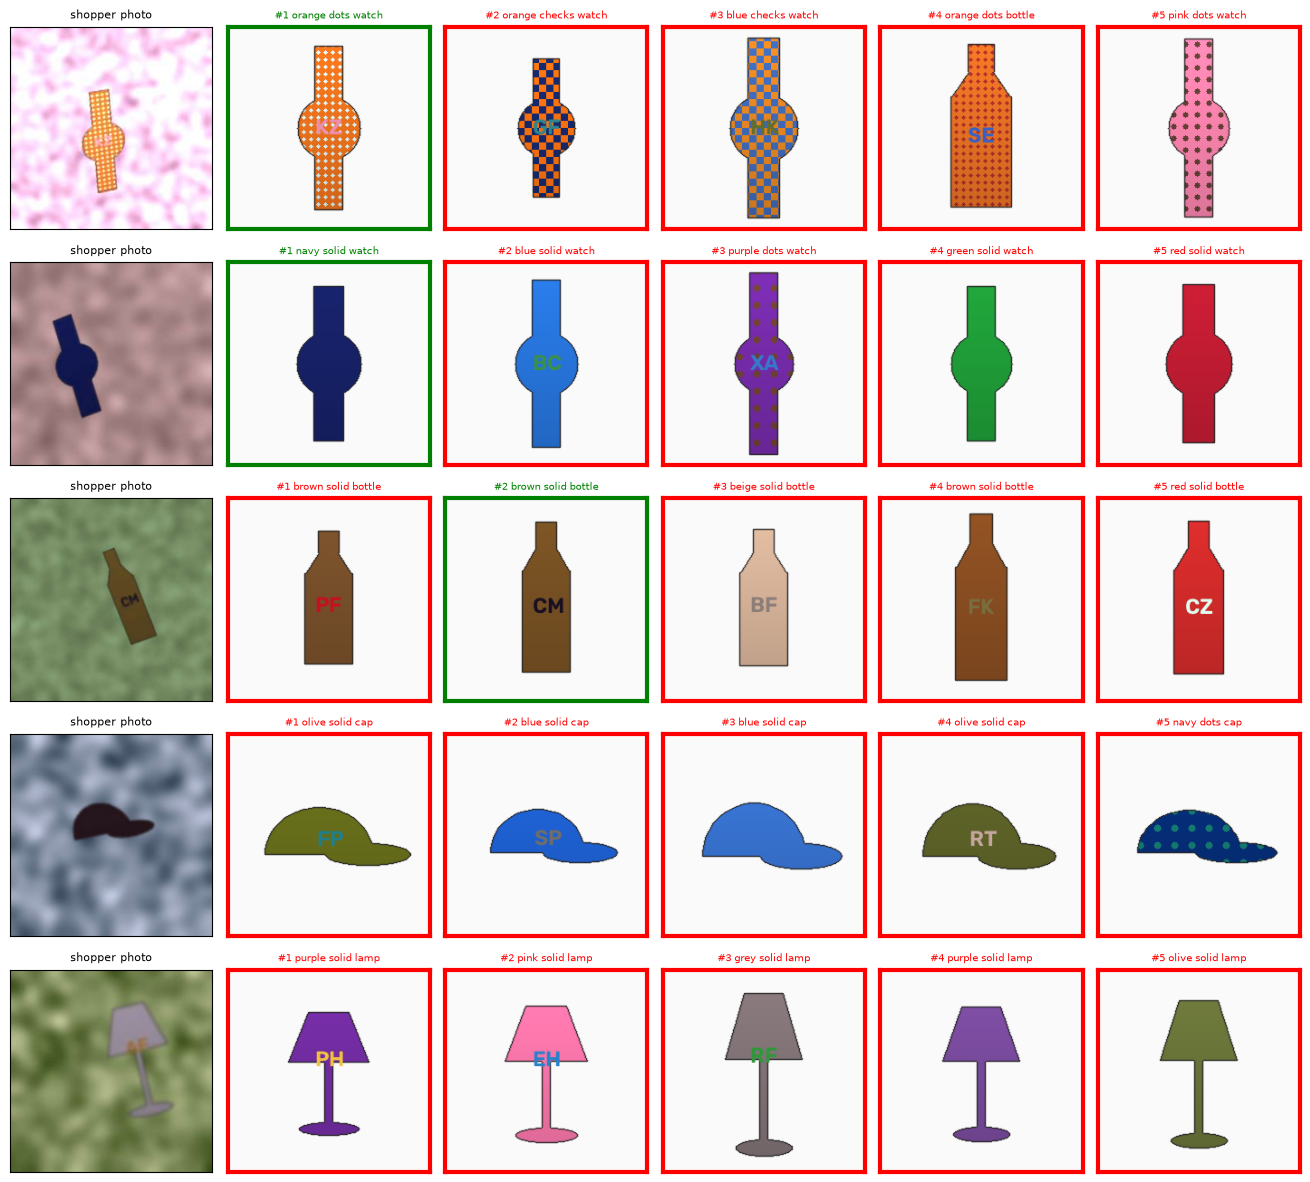

In [10]:
def show_results(query_ids, result_positions, n_show=5):
    fig, axes = plt.subplots(len(query_ids), n_show + 1, figsize=(2.2 * (n_show + 1), 2.4 * len(query_ids)))
    for row, q in enumerate(query_ids):
        axes[row, 0].imshow(query_images[q]); axes[row, 0].set_title("shopper photo", fontsize=8)
        for col in range(n_show):
            pos = result_positions[q, col]
            ok = catalog.product_group[pos] == query_truth[q]
            ax = axes[row, col + 1]
            ax.imshow(catalog_images[pos])
            ax.set_title(f"#{col + 1} {catalog.title[pos]}", fontsize=7, color="green" if ok else "red")
            for spine in ax.spines.values():
                spine.set_edgecolor("green" if ok else "red"); spine.set_linewidth(3)
    for ax in axes.ravel():
        ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); plt.show()


groups = catalog["product_group"].to_numpy()
hit_rank = np.array([np.flatnonzero(groups[best_result[q]] == query_truth[q])[0] + 1
                     if (groups[best_result[q]] == query_truth[q]).any() else 0 for q in range(len(query_truth))])
examples = list(np.flatnonzero(hit_rank == 1)[:2]) + list(np.flatnonzero(hit_rank > 1)[:1]) + list(np.flatnonzero(hit_rank == 0)[:2])
show_results(examples, best_result)

Typical pattern: when the search is "wrong", the results still look **plausible** (similar shape). Let's check with numbers what the wrong top-1 results have in common with the photographed product, and how search quality differs per category:

In [11]:
top1 = best_result[:, 0]
analysis = products[["category", "color", "pattern"]].assign(
    hit_at_10=hit_rank > 0, hit_at_1=hit_rank == 1,
    top1_same_category=catalog.category.to_numpy()[top1] == products.category.to_numpy(),
    top1_same_color=catalog.color.to_numpy()[top1] == products.color.to_numpy())
misses = analysis[~analysis.hit_at_1]
print(f"When the top-1 result is wrong ({len(misses)} queries):")
print(f"  it has the same category in {misses.top1_same_category.mean():.0%} of cases")
print(f"  it has the same main colour in {misses.top1_same_color.mean():.0%} of cases\n")
analysis.groupby("category")[["hit_at_1", "hit_at_10"]].mean().round(2).sort_values("hit_at_10")

When the top-1 result is wrong (174 queries):
  it has the same category in 91% of cases
  it has the same main colour in 18% of cases



,hit_at_1,hit_at_10
category,,
lamp,0.55,0.84
bottle,0.61,0.92
mug,0.50,0.92
watch,0.45,0.94
t-shirt,0.51,0.96
backpack,0.53,0.98
cap,0.65,0.98
sneaker,0.73,0.98


The wrong top-1 result is almost always from the **same category**, but usually **not** the same main colour: ImageNet features care much more about shape than about exact colour. That suggests a cheap product fix (let the shopper filter by colour, or re-rank the top candidates by a colour feature) before investing in a new model.

A per-category table like this tells the product team **where** visual search works well and where to invest (more data, a fine-tuned model, or showing text filters next to the results).

---
## 10. Near-duplicate detection (duplicate listings)

When a seller uploads a product photo, we want to warn: *"This looks like an existing listing (SKU 10234)."* Duplicates clutter results (the shopper sees the same item twice) and can be a sign of fraud.

**First idea:** embed the upload, find its nearest neighbour, and call it a duplicate if the cosine similarity is above a threshold. To pick any threshold honestly:
1. collect candidate pairs (each listing with its 5 nearest neighbours) and label them (here we know which listings are duplicates),
2. choose the threshold on **half** of the products (calibration),
3. check precision and recall on the **other half**.

For duplicate detection we use the plain single-view embeddings: we want "same photo", not "same product from several angles".

In [12]:
sims, nbrs = exact_search(cnn_catalog, cnn_catalog, 6)                 # self + 5 nearest neighbours
pairs = pd.DataFrame([(i, j, s) for i in range(len(catalog)) for j, s in zip(nbrs[i, 1:], sims[i, 1:]) if i < j],
                     columns=["a", "b", "cosine"])
pairs["is_duplicate"] = groups[pairs.a] == groups[pairs.b]
pairs["calibration_half"] = groups[pairs.a] % 2 == 0                    # split by product, not by pair
print(f"{len(pairs)} candidate pairs, {pairs.is_duplicate.sum()} of them are true duplicates "
      f"(out of {CFG.n_duplicate_listings} duplicate listings)")


def choose_threshold(df, column, candidates, higher_means_duplicate=True):
    """Pick the threshold with the best F1 on the calibration half; report both halves."""
    def precision_recall(part, thr):
        flagged = part[column] >= thr if higher_means_duplicate else part[column] <= thr
        tp = (flagged & part.is_duplicate).sum()
        return tp / max(flagged.sum(), 1), tp / max(part.is_duplicate.sum(), 1)
    calib, held_out = df[df.calibration_half], df[~df.calibration_half]
    f1 = [2 * p * r / max(p + r, 1e-9) for p, r in (precision_recall(calib, t) for t in candidates)]
    thr = float(candidates[int(np.argmax(f1))])
    (pc, rc), (ph, rh) = precision_recall(calib, thr), precision_recall(held_out, thr)
    return thr, {"threshold": thr, "precision (calibration)": round(pc, 2), "recall (calibration)": round(rc, 2),
                 "precision (held-out)": round(ph, 2), "recall (held-out)": round(rh, 2)}


COSINE_DUP_THRESHOLD, cosine_report = choose_threshold(pairs, "cosine", np.round(np.arange(0.80, 1.0, 0.0025), 4))
print(pd.Series(cosine_report).to_string())

look_alikes = pairs[~pairs.is_duplicate].nlargest(3, "cosine")
print("\nMost similar DIFFERENT products:")
for _, r in look_alikes.iterrows():
    print(f"  cosine {r.cosine:.3f}: {catalog.title[r.a]} '{catalog.logo[r.a]}'  vs  {catalog.title[r.b]} '{catalog.logo[r.b]}'")

1082 candidate pairs, 39 of them are true duplicates (out of 40 duplicate listings)
threshold                  0.97
precision (calibration)    0.57
recall (calibration)       0.57
precision (held-out)       0.41
recall (held-out)          0.50

Most similar DIFFERENT products:
  cosine 0.992: navy solid t-shirt ''  vs  navy solid t-shirt ''
  cosine 0.987: yellow checks t-shirt 'XP'  vs  orange checks t-shirt 'CF'
  cosine 0.980: black solid t-shirt ''  vs  black solid t-shirt ''


Read the numbers above: with the embedding alone, precision and recall stay far from what a moderation team needs. The reason is visible in the list of "most similar different products": items of the same category with similar colours or patterns (often plain ones) get almost identical embeddings. An ImageNet model was trained to say *"this is a mug"*, and is deliberately **insensitive** to exact colour shade, small size changes or a logo. That is great for "find similar products" and bad for "is this the *same photo*?".

**Industry fix: a two-stage check.**
1. **Stage 1 (recall):** the embedding index proposes a few candidates (top 5), which is fast even for millions of listings.
2. **Stage 2 (precision):** a cheap, exact pixel-level comparison verifies each candidate. We compare tiny **32×32 colour thumbnails** (brightness-normalised, background ignored) by their median absolute difference. Re-uploads of the same photo stay very close; look-alikes with another shade, logo or shape do not. (Perceptual hashes such as pHash, or local-feature matching with ORB/SIFT, are other common choices for this stage.)

A thumbnail is only 3 KB, so production systems simply store one next to every listing.

                                  threshold  precision (calibration)  recall (calibration)  precision (held-out)  recall (held-out)
embedding cosine only                  0.97                     0.57                  0.57                  0.41               0.50
top-5 by embedding + pixel check       5.50                     0.67                  0.95                  0.54               0.78


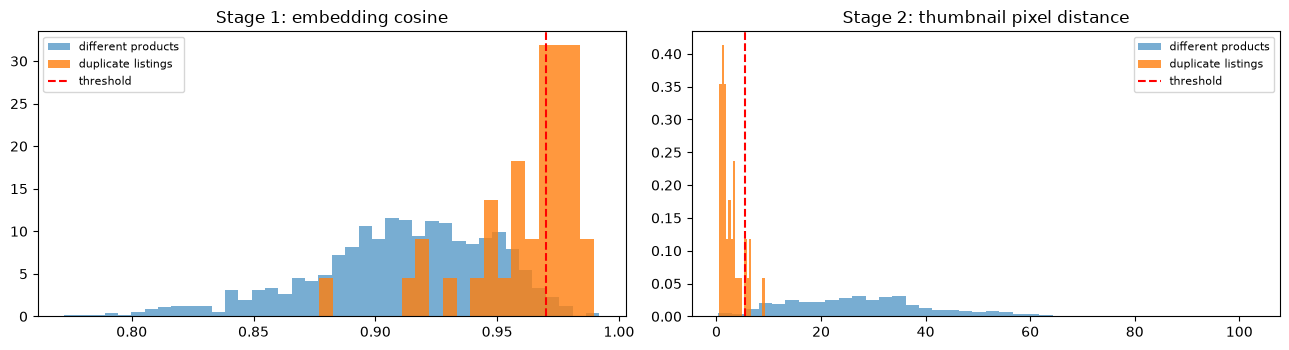

In [13]:
def thumbnail(img: np.ndarray):
    """32x32 colour thumbnail (brightness-normalised) + mask of non-background pixels."""
    small = cv2.resize(img, (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32)
    foreground = small.min(axis=2) < 235                         # not (almost) white studio background
    return small * (128.0 / max(small.mean(), 1.0)), foreground


def pixel_distance(thumb_a, thumb_b) -> float:
    """Median absolute colour difference on the product pixels (robust to a small 'SALE' banner)."""
    (a, fg_a), (b, fg_b) = thumb_a, thumb_b
    fg = fg_a | fg_b
    return float(np.median(np.abs(a - b)[fg])) if fg.any() else 0.0


catalog_thumbs = {sku: thumbnail(im) for sku, im in zip(catalog.sku, catalog_images)}   # stored per listing
skus = catalog.sku.to_numpy()
pairs["pixel_distance"] = [pixel_distance(catalog_thumbs[skus[a]], catalog_thumbs[skus[b]]) for a, b in zip(pairs.a, pairs.b)]
PIXEL_DUP_THRESHOLD, pixel_report = choose_threshold(pairs, "pixel_distance", np.arange(1.0, 15.0, 0.5),
                                                     higher_means_duplicate=False)
print(pd.DataFrame({"embedding cosine only": cosine_report,
                    "top-5 by embedding + pixel check": pixel_report}).T.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, col, thr, title in [(axes[0], "cosine", COSINE_DUP_THRESHOLD, "Stage 1: embedding cosine"),
                            (axes[1], "pixel_distance", PIXEL_DUP_THRESHOLD, "Stage 2: thumbnail pixel distance")]:
    ax.hist(pairs[col][~pairs.is_duplicate], bins=40, alpha=.6, label="different products", density=True)
    ax.hist(pairs[col][pairs.is_duplicate], bins=20, alpha=.8, label="duplicate listings", density=True)
    ax.axvline(thr, color="red", ls="--", label="threshold"); ax.set_title(title); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Compare the two rows of the table and the two plots: in the embedding plot the duplicates are buried inside the look-alikes, while the pixel distance separates them clearly better (higher precision *and* recall on the held-out half). It is still not perfect: some flagged pairs are genuine look-alikes (e.g. two plain t-shirts of nearly the same colour), which even a human would need to open to decide. Recall is capped by stage 1 (a duplicate that is not among the 5 nearest neighbours is never checked) and by heavier edits (crops, banners). A common production design adds a **grey zone**: very small distances are merged automatically, borderline ones go to a human moderator.

---
## 11. Scaling up: exact vs approximate indexes

`IndexFlatIP` compares the query with **every** vector. That is perfect (exact) and fine for thousands of items, but at millions of items it becomes slow and memory-hungry. **Approximate nearest neighbour (ANN)** indexes trade a little accuracy for a lot of speed:

| Index | Idea | Main knob |
|---|---|---|
| `IndexFlatIP` | compare with everything (exact) | none |
| `IndexIVFFlat` | cluster vectors into `nlist` buckets; search only the `nprobe` closest buckets | `nprobe` |
| `IndexHNSWFlat` | navigable graph of neighbours; walk the graph towards the query | `efSearch` |
| `IndexIVFPQ` | IVF + **product quantization**: compress each vector to a few bytes | `nprobe`, code size |

To make the speed differences visible, we **pad the index with 30,000 simulated filler vectors** drawn from a Gaussian with the same mean and covariance as our real embeddings (rendering 30,000 images would take too long on a CPU). The filler items are "other products": if a query returns one of them, it counts as a miss, just like in a big real catalog.

We measure for each index:
- **ANN recall@10**: overlap of its top-10 with the exact top-10 (how well it approximates exact search),
- **product recall@10**: our business metric on the real shopper photos,
- **latency per query** (one query at a time, 1 thread, like an online request), **build time** and **memory**.

FAISS guideline used for IVF: `nlist` ≈ 4·√N to 16·√N buckets.

In [14]:
real_vecs = catalog_vecs
mean, cov = real_vecs.mean(axis=0), np.cov(real_vecs, rowvar=False)
filler = l2_normalize(np.random.default_rng(CFG.seed).multivariate_normal(mean, cov, CFG.n_filler_vectors,
                                                                          method="eigh").astype(np.float32))
big_vecs = np.vstack([real_vecs, filler])                  # real listings first, so positions < len(catalog) are real
N, D = big_vecs.shape
print(f"Index size: {N:,} vectors x {D} dims = {big_vecs.nbytes / 1e6:.0f} MB of raw float32")

exact_index = faiss.IndexFlatIP(D); exact_index.add(big_vecs)
_, exact_top = exact_index.search(cnn_queries, CFG.top_k)            # ground truth for ANN recall


def index_memory_mb(index) -> float:
    return faiss.serialize_index(index).nbytes / 1e6                # size of the index in bytes


def benchmark(name, index, build_seconds, n_latency_queries=200):
    _, top = index.search(cnn_queries, CFG.top_k)                   # all queries, for the quality metrics
    ann_recall = np.mean([len(set(a) & set(b)) / CFG.top_k for a, b in zip(top, exact_top)])
    top_real = np.where(top < len(catalog), top, 0)                  # filler positions -> placeholder
    found = (groups[top_real] == query_truth[:, None]) & (top < len(catalog))
    faiss.omp_set_num_threads(1)                                     # online serving: one request at a time
    times = []
    for q in cnn_queries[:n_latency_queries]:
        t0 = time.perf_counter()
        index.search(q[None, :], CFG.top_k)
        times.append(time.perf_counter() - t0)
    latency_ms = float(np.median(times)) * 1000                     # median: robust to hiccups of a busy CPU
    faiss.omp_set_num_threads(CFG.num_threads)
    return {"index": name, "ANN recall@10": round(ann_recall, 3), "product recall@10": round(found.any(1).mean(), 3),
            "ms / query": round(latency_ms, 3), "build s": round(build_seconds, 1), "memory MB": round(index_memory_mb(index), 1)}


bench = [benchmark("Flat (exact)", exact_index, 0.0)]

# --- IVF: k-means buckets ---
nlist = int(4 * np.sqrt(N))                                          # FAISS guideline: 4*sqrt(N) .. 16*sqrt(N)
t0 = time.time()
ivf_quantizer = faiss.IndexFlatIP(D)                               # finds the closest buckets (keep a reference!)
ivf = faiss.IndexIVFFlat(ivf_quantizer, D, nlist, faiss.METRIC_INNER_PRODUCT)
ivf.train(big_vecs); ivf.add(big_vecs)
ivf_build = time.time() - t0
for nprobe in [1, 8, 32]:
    ivf.nprobe = nprobe
    bench.append(benchmark(f"IVF{nlist} nprobe={nprobe}", ivf, ivf_build))

# --- HNSW: graph ---
t0 = time.time()
hnsw = faiss.IndexHNSWFlat(D, 32, faiss.METRIC_INNER_PRODUCT)       # M = 32 neighbours per node
hnsw.hnsw.efConstruction = 64
hnsw.add(big_vecs)
hnsw_build = time.time() - t0
for ef in [16, 64, 256]:
    hnsw.hnsw.efSearch = ef
    bench.append(benchmark(f"HNSW32 efSearch={ef}", hnsw, hnsw_build))

# --- IVF-PQ: compressed vectors (48 bytes instead of 576 * 4 = 2304 bytes) ---
t0 = time.time()
pq_quantizer = faiss.IndexFlatIP(D)
ivfpq = faiss.IndexIVFPQ(pq_quantizer, D, nlist, 48, 8, faiss.METRIC_INNER_PRODUCT)   # 48 sub-vectors x 8 bits
ivfpq.train(big_vecs); ivfpq.add(big_vecs)
ivfpq.nprobe = 32
bench.append(benchmark("IVF-PQ48 nprobe=32", ivfpq, time.time() - t0))

bench_df = pd.DataFrame(bench)
bench_df

Index size: 30,440 vectors x 576 dims = 70 MB of raw float32


,index,ANN recall@10,product recall@10,ms / query,build s,memory MB
0,Flat (exact),1.000,0.825,9.396,0.0,70.1
1,IVF697 nprobe=1,0.371,0.455,0.125,9.0,72.0
2,IVF697 nprobe=8,0.757,0.765,0.235,9.0,72.0
3,IVF697 nprobe=32,0.940,0.815,0.503,9.0,72.0
4,HNSW32 efSearch=16,0.909,0.812,0.171,16.2,78.4
5,HNSW32 efSearch=64,0.992,0.825,0.485,16.2,78.4
6,HNSW32 efSearch=256,1.000,0.825,1.357,16.2,78.4
7,IVF-PQ48 nprobe=32,0.628,0.760,0.456,29.4,3.9


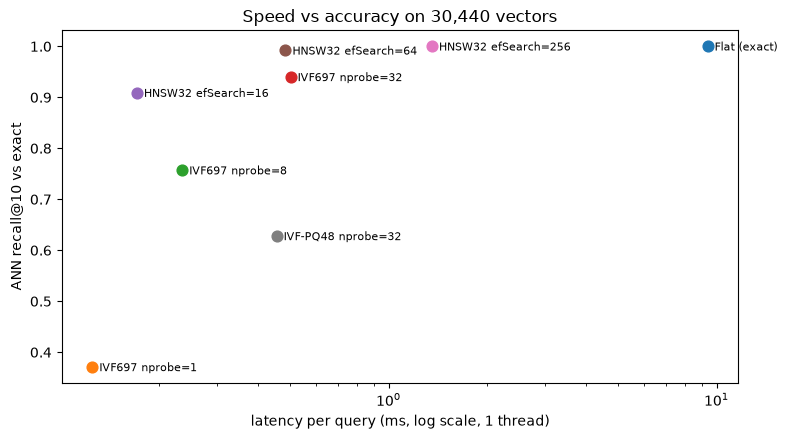

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for _, r in bench_df.iterrows():
    ax.scatter(r["ms / query"], r["ANN recall@10"], s=60)
    ax.annotate(r["index"], (r["ms / query"], r["ANN recall@10"]), fontsize=8, xytext=(5, -3), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("latency per query (ms, log scale, 1 thread)"); ax.set_ylabel("ANN recall@10 vs exact")
ax.set_title(f"Speed vs accuracy on {N:,} vectors")
plt.tight_layout(); plt.show()

**How to read the benchmark** (check the numbers in the table above):
- **Flat** is the reference: ANN recall 1.0 by definition, and the slowest per query because it touches every vector.
- **IVF** with a small `nprobe` is very fast but misses neighbours that sit in a different bucket; increasing `nprobe` buys back accuracy at the cost of speed.
- **HNSW** usually gives the best speed/recall trade-off in RAM, at the price of extra memory for the graph and a slower build. It cannot delete vectors.
- **IVF-PQ** uses a fraction of the memory, but the compression loses accuracy. That is the option for hundreds of millions of vectors.
- The **product recall@10** column is the one the business sees. Compare it with the ANN recall: a small ANN loss often costs much less in product recall, because the embedding itself is the bigger source of errors.
- Even the exact Flat index has a **lower product recall@10 than in Section 8**: the 30,000 extra items now compete for the 10 slots. Bigger catalogs are harder (more look-alikes), which is one more reason to improve the embedding as the catalog grows. (Our filler vectors are random, so treat this drop as an illustration, not a forecast.)
- Latencies are measured on a possibly busy, shared CPU; the *ranking* between index types is what matters, not the exact milliseconds.

Rules of thumb from the FAISS wiki: below ~1M vectors, Flat or HNSW; 1M-100M, IVF (often with HNSW as the bucket finder) and maybe PQ; and always measure on **your** data, as we did here. At larger scale companies use the same ideas through vector databases (Milvus, Qdrant, Weaviate, pgvector, Elasticsearch/OpenSearch k-NN); see `13_Databases/03_vector_db/01_vector_databases.ipynb`.

---
## 12. Adding and removing products

The catalog changes every day. FAISS indexes differ in what they support:

| Index | Add new items | Remove items | Note |
|---|---|---|---|
| Flat (wrapped in `IndexIDMap2`) | ✔ instantly | ✔ `remove_ids` | simplest, exact |
| IVF | ✔ (no re-training needed) | ✔ | re-train buckets when the catalog drifts a lot |
| HNSW | ✔ | ✘ | mark deleted items and filter them, rebuild nightly |

We wrap a Flat index in `IndexIDMap2` so we can use our own **SKU numbers as IDs** instead of row positions (row positions shift when items are removed, SKUs do not).

In [16]:
# The production index: exact search, addressed by SKU
flat_storage = faiss.IndexFlatIP(D)                                  # the vectors themselves
sku_index = faiss.IndexIDMap2(flat_storage)                          # + a mapping position <-> SKU
sku_index.add_with_ids(catalog_vecs, catalog["sku"].to_numpy().astype(np.int64))
print("Listings in index:", sku_index.ntotal)

# A new batch of products arrives from the catalog team
new_products = make_products(CFG.n_new_products, rng, first_id=20000)
new_images = [render_product(p) for p in new_products.to_dict("records")]
new_vecs = embed_catalog_multiview(new_images) if use_multiview else embed_images(new_images)
sku_index.add_with_ids(new_vecs, new_products["sku"].to_numpy().astype(np.int64))
catalog = pd.concat([catalog, new_products.assign(duplicate_of=-1, product_group=new_products.sku)], ignore_index=True)
catalog_images += new_images
catalog_thumbs.update({sku: thumbnail(im) for sku, im in zip(new_products.sku, new_images)})   # for duplicate checks
print("After adding new products:", sku_index.ntotal)

# Can shoppers find them right away?
new_queries = embed_images([shopper_photo(p, rng) for p in new_products.to_dict("records")])
_, found_ids = sku_index.search(new_queries, CFG.top_k)
print(f"New products found in top-10 by a shopper photo: {np.mean([s in row for s, row in zip(new_products.sku, found_ids)]):.0%}")

# Some products are discontinued: remove them by SKU
discontinued = new_products["sku"].to_numpy()[:5].astype(np.int64)
sku_index.remove_ids(discontinued)
_, after = sku_index.search(new_queries[:5], CFG.top_k)
print("After removal:", sku_index.ntotal, "| discontinued SKUs still returned:", int(np.isin(after, discontinued).sum()))
catalog = catalog[~catalog.sku.isin(discontinued)].reset_index(drop=True)
for sku in discontinued:
    catalog_thumbs.pop(int(sku))

Listings in index: 440


After adding new products: 480


New products found in top-10 by a shopper photo: 95%
After removal: 475 | discontinued SKUs still returned: 0


---
## 13. The search service

Everything comes together in one class, as it would sit behind an API endpoint (`POST /search-by-photo`, see `12_FastAPI/03_ml_serving_with_fastapi.ipynb`):
1. normalise and validate the photo (`to_rgb_uint8`),
2. embed it with **the same** `embed_images` function used for the catalog,
3. search the SKU index,
4. **merge duplicate listings** (show each real product once),
5. return product information and similarity scores.

It also offers `check_upload` for sellers: is this new photo a near-duplicate of an existing listing? It uses the two-stage check from Section 10 (embedding candidates, then thumbnail verification).

In [17]:
class VisualSearchService:
    def __init__(self, index, catalog_table: pd.DataFrame, thumbs: dict, pixel_threshold: float):
        self.index = index
        self.catalog = catalog_table.set_index("sku")
        self.thumbs = thumbs                                          # sku -> 32x32 thumbnail (for duplicates)
        self.pixel_threshold = pixel_threshold

    def _embed(self, image) -> np.ndarray:
        return embed_images([to_rgb_uint8(image)])                    # raises ValueError for bad input

    def search(self, image, k: int = CFG.top_k) -> pd.DataFrame:
        sims, skus = self.index.search(self._embed(image), k * 3)    # ask for more, duplicates get merged
        rows, seen_groups = [], set()
        for sku, sim in zip(skus[0], sims[0]):
            if sku < 0:                                               # FAISS returns -1 if it has fewer results
                continue
            item = self.catalog.loc[sku]
            if item.product_group in seen_groups:                     # same real product already listed
                continue
            seen_groups.add(item.product_group)
            rows.append({"rank": len(rows) + 1, "sku": int(sku), "title": item.title, "similarity": round(float(sim), 3)})
            if len(rows) == k:
                break
        return pd.DataFrame(rows)

    def check_upload(self, image, n_candidates: int = 5) -> dict:
        img = to_rgb_uint8(image)
        _, skus = self.index.search(embed_images([img]), n_candidates)      # stage 1: candidates
        upload_thumb = thumbnail(img)
        distances = {int(s): pixel_distance(upload_thumb, self.thumbs[int(s)]) for s in skus[0] if s >= 0}
        closest = min(distances, key=distances.get)                          # stage 2: pixel verification
        return {"is_near_duplicate": distances[closest] <= self.pixel_threshold, "closest_sku": closest,
                "pixel_distance": round(distances[closest], 2)}


service = VisualSearchService(sku_index, catalog, catalog_thumbs, PIXEL_DUP_THRESHOLD)

q = int(np.flatnonzero(hit_rank == 1)[0])
print(f"Shopper photographed SKU {query_truth[q]} ({products.title[q]}):")
print(service.search(query_images[q], k=5).to_string(index=False))

print("\nSeller uploads a re-cropped copy of an existing listing:", service.check_upload(reupload(catalog_images[3], rng)))
print("Seller uploads a brand-new product                    :", service.check_upload(render_product(make_products(1, rng, 30000).iloc[0].to_dict())))
try:
    service.search(np.zeros((32, 32, 3), np.uint8))
except ValueError as err:
    print("Bad request rejected:", err)

Shopper photographed SKU 10000 (orange dots watch):
 rank   sku               title  similarity
    1 10000   orange dots watch       0.798
    2 10063 orange checks watch       0.735
    3 10236   blue checks watch       0.714
    4 10250  orange dots bottle       0.701
    5 10147     pink dots watch       0.698



Seller uploads a re-cropped copy of an existing listing: {'is_near_duplicate': True, 'closest_sku': 10003, 'pixel_distance': 1.18}


Seller uploads a brand-new product                    : {'is_near_duplicate': False, 'closest_sku': 10312, 'pixel_distance': 18.54}
Bad request rejected: image too small (32, 32), need at least 64px


---
## 14. Save and reload the index

The index is built by an **offline job** (e.g. nightly with Airflow, plus incremental adds during the day) and loaded by the API servers. We save:
- the FAISS index (`faiss.write_index`),
- the SKU table it refers to,
- **metadata**: which model and preprocessing produced the vectors. A query embedded with a *different* model version would be compared with incompatible vectors and return garbage, without any error. Recording the embedding model version next to the index prevents that.

We save to a temporary folder; in a real project this would be object storage such as `s3://search-index/visual/v1/`.

In [18]:
ARTIFACT_DIR = Path(tempfile.mkdtemp(prefix="visual_search_"))       # real life: s3://search-index/visual/v1/
faiss.write_index(sku_index, str(ARTIFACT_DIR / "catalog.faiss"))
catalog[["sku", "title", "category", "color", "pattern", "product_group"]].to_csv(ARTIFACT_DIR / "catalog.csv", index=False)
np.savez_compressed(ARTIFACT_DIR / "thumbnails.npz", skus=np.array(list(catalog_thumbs)),
                    pixels=np.stack([t for t, _ in catalog_thumbs.values()]),
                    masks=np.stack([m for _, m in catalog_thumbs.values()]))
metadata = {
    "index_type": "IndexIDMap2(IndexFlatIP)", "n_vectors": int(sku_index.ntotal), "dim": D,
    "embedding_model": "torchvision mobilenet_v3_small IMAGENET1K_V1, avgpool output, L2-normalised",
    "multiview_catalog": bool(use_multiview),
    "preprocessing": str(PREPROCESS).replace("\n", " "),
    "near_duplicate_pixel_threshold": PIXEL_DUP_THRESHOLD,
    "eval_metrics": results,
    "built_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "versions": {"torch": torch.__version__, "torchvision": torchvision.__version__, "faiss": faiss.__version__},
    "config": asdict(CFG),
}
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2, default=str))
for f in sorted(ARTIFACT_DIR.iterdir()):
    print(f"{f.name:16s} {f.stat().st_size / 1e6:7.2f} MB")

# A fresh API server starts and loads the files
reloaded = faiss.read_index(str(ARTIFACT_DIR / "catalog.faiss"))
saved = np.load(ARTIFACT_DIR / "thumbnails.npz")
reloaded_thumbs = {int(s): (p, m) for s, p, m in zip(saved["skus"], saved["pixels"], saved["masks"])}
reloaded_service = VisualSearchService(reloaded, pd.read_csv(ARTIFACT_DIR / "catalog.csv"), reloaded_thumbs,
                                       json.loads((ARTIFACT_DIR / "metadata.json").read_text())["near_duplicate_pixel_threshold"])
same = reloaded_service.search(query_images[q]).sku.tolist() == service.search(query_images[q]).sku.tolist()
print("Reloaded index returns identical results:", same)

catalog.csv         0.02 MB


catalog.faiss       1.10 MB
metadata.json       0.00 MB
thumbnails.npz      0.49 MB


Reloaded index returns identical results: True


---
## 15. Latency and memory summary

End-to-end latency = **embedding the photo** (CNN) + **searching** the index. On a CPU the CNN is usually the larger part, which is why companies pick small backbones or run the embedding on a GPU / with ONNX Runtime.

In [19]:
photo = query_images[q]
for _ in range(3):
    service.search(photo)                                                # warm-up

def measure_ms(fn, n=30):
    times = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); times.append((time.perf_counter() - t0) * 1000)
    return np.percentile(times, [50, 95])

embed_p50, embed_p95 = measure_ms(lambda: embed_images([photo]))
total_p50, total_p95 = measure_ms(lambda: service.search(photo))
model_mb = sum(p.numel() * p.element_size() for p in backbone.parameters()) / 1e6

summary = pd.DataFrame({
    "value": [f"{embed_p50:.1f} / {embed_p95:.1f} ms", f"{total_p50:.1f} / {total_p95:.1f} ms",
              f"{CFG.latency_budget_ms:.0f} ms", f"{model_mb:.1f} MB",
              f"{D * 4} bytes", f"{index_memory_mb(sku_index):.1f} MB for {sku_index.ntotal} items",
              f"~{D * 4 * 1e6 / 1e9:.1f} GB (Flat) vs ~{(48 + 8) * 1e6 / 1e9:.2f} GB (IVF-PQ48 codes + ids)"]},
    index=["embedding p50 / p95", "end-to-end search p50 / p95", "latency budget", "CNN weights",
           "one embedding (float32)", "production index (Flat)", "1 million products would need"])
print(f"p95 end-to-end {total_p95:.0f} ms vs budget {CFG.latency_budget_ms:.0f} ms -> "
      f"{'within budget' if total_p95 <= CFG.latency_budget_ms else 'OVER budget on this machine right now'}")
print(f"Share of end-to-end time spent in the CNN (median): {embed_p50 / total_p50:.0%}")
summary

p95 end-to-end 121 ms vs budget 100 ms -> OVER budget on this machine right now
Share of end-to-end time spent in the CNN (median): 99%


,value
embedding p50 / p95,40.8 / 63.5 ms
end-to-end search p50 / p95,41.4 / 121.4 ms
latency budget,100 ms
CNN weights,10.2 MB
one embedding (float32),2304 bytes
production index (Flat),1.1 MB for 475 items
1 million products would need,~2.3 GB (Flat) vs ~0.06 GB (IVF-PQ48 codes + ids)


Compare the end-to-end numbers with the 100 ms budget. They depend heavily on the machine and on what else is running: MobileNetV3-Small needs only about 60 million multiply-adds per image, which takes a few milliseconds on an idle modern CPU core, but on a busy, shared machine (as when this notebook was executed) it is several times slower and has occasional slow outliers, which push up the p95. That is exactly why production services run on **dedicated** CPU/GPU capacity, are load-tested, and are monitored by **p95/p99 latency**, not just the average. Notice also that almost all of the end-to-end time is spent in the CNN, not in the index search: optimise the embedding step first (ONNX Runtime, int8 quantisation, batching requests, or a GPU). The memory line shows why compression (PQ) or a vector database becomes necessary at millions of products: 2.3 KB per vector is fine for 1,000 items and painful for 100 million.

---
## 16. Automated tests

Tests that would run in CI before a new index or model version is deployed:

In [20]:
def test_embeddings_are_normalised():
    assert np.allclose(np.linalg.norm(embed_images(catalog_images[:5]), axis=1), 1.0, atol=1e-5)


def test_service_uses_same_preprocessing_as_catalog():
    """A catalog image searched through the service must find itself with similarity ~1 (single-view index)."""
    probe_storage = faiss.IndexFlatIP(D)
    probe = faiss.IndexIDMap2(probe_storage)
    probe.add_with_ids(cnn_catalog[:50], catalog.sku.to_numpy()[:50].astype(np.int64))
    sims, ids = probe.search(service._embed(catalog_images[7]), 1)
    assert ids[0, 0] == catalog.sku[7] and sims[0, 0] > 0.999


def test_grayscale_and_rgba_inputs_work():
    assert len(service.search(query_images[0][:, :, 0], k=3)) == 3
    assert len(service.search(np.dstack([query_images[0], np.full(query_images[0].shape[:2], 255, np.uint8)]), k=3)) == 3


def test_results_have_no_duplicate_products():
    res = service.search(query_images[dup_src[0]], k=10)
    assert service.catalog.loc[res.sku, "product_group"].is_unique


def test_quality_gate():
    """Never deploy an embedding that is worse than the simple baseline or below the agreed minimum."""
    best = results["CNN + multi-view catalog" if use_multiview else "CNN embedding (MobileNetV3)"]
    assert best["recall@10"] > results["colour histogram (baseline)"]["recall@10"]
    assert best["recall@10"] >= 0.5


for test in [test_embeddings_are_normalised, test_service_uses_same_preprocessing_as_catalog,
             test_grayscale_and_rgba_inputs_work, test_results_have_no_duplicate_products, test_quality_gate]:
    test()
    print(f"PASSED  {test.__name__}")

PASSED  test_embeddings_are_normalised
PASSED  test_service_uses_same_preprocessing_as_catalog


PASSED  test_grayscale_and_rgba_inputs_work
PASSED  test_results_have_no_duplicate_products
PASSED  test_quality_gate


---
## 17. Summary, exercises and resources

| Practice | What we did | Where it is used in industry |
|---|---|---|
| Ground truth for search | known augmented copies, duplicate groups | Golden query sets, click logs |
| Input normalisation | grayscale / RGBA / 16-bit / tiny / blank handling | Every image upload API |
| Baseline first | colour histograms | Proves the CNN is worth it |
| Correct preprocessing | `weights.transforms()` shared by catalog and queries | Avoids silent quality loss |
| Penultimate-layer embeddings + L2 norm | cosine similarity via inner product | Image search, recommendations, dedup |
| Retrieval metrics | recall@k, mAP@10 | Search and recommender evaluation |
| Multi-view catalog vectors | average of a few fixed views | Cheap robustness without training |
| Near-duplicate threshold | calibrated on half, checked on the other half | Marketplace moderation, data cleaning |
| Exact vs ANN indexes | Flat, IVF, HNSW, IVF-PQ benchmark | Vector databases, large-scale search |
| SKU-addressed index | `IndexIDMap2`, add / remove | Daily catalog updates |
| Service + saving + metadata | `VisualSearchService`, `write_index`, model version | API servers, index build jobs |
| Latency, memory, tests | p50/p95, bytes per vector, CI tests | Production readiness |

### Practice exercises
1. Replace MobileNetV3-Small with ResNet-18 (`torchvision.models.resnet18`, 512-dim embeddings, ≈45 MB download). Does recall@10 improve? What happens to latency?
2. Remove the multi-view averaging and instead store **all three views as separate vectors** (3 vectors per SKU, merge by SKU at query time). Compare recall and memory.
3. Re-run Section 11 with `M = 16` and `M = 64` for HNSW. How do memory, build time and recall change?
4. Add a **category filter** to `VisualSearchService.search` (e.g. only "sneaker"): search for more candidates, then filter. When does this fail? (Hint: rare categories; vector databases support filtered search natively.)
5. Fine-tuning challenge: train a small linear projection on top of the frozen embeddings with a contrastive loss, using two different augmented views of each catalog image as positive pairs. Evaluate it on the shopper photos.

### Resources
- FAISS wiki, *Getting started* and *Guidelines to choose an index*: https://github.com/facebookresearch/faiss/wiki/Getting-started and https://github.com/facebookresearch/faiss/wiki/Guidelines-to-choose-an-index
- timm documentation, *Feature Extraction* (penultimate-layer features with `num_classes=0`): https://huggingface.co/docs/timm/feature_extraction
- PyTorch tutorial, *Transfer Learning for Computer Vision* (preprocessing and pretrained models): https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html
- Kaggle competition *Shopee - Price Match Guarantee* (real product matching from images and titles; winning solutions used metric learning): https://www.kaggle.com/competitions/shopee-product-matching
- HNSW paper (Malkov & Yashunin): https://arxiv.org/abs/1603.09320 and Product Quantization paper (Jégou et al.): https://ieeexplore.ieee.org/document/5432202

### Related notebooks in this repo
- A script version of image similarity search: [`projects/03_image_similarity.py`](projects/03_image_similarity.py)
- CNNs and transfer learning: [`02_image_classification.ipynb`](02_image_classification.ipynb), [`05_vision_transformers.ipynb`](05_vision_transformers.ipynb) (CLIP for text-to-image search)
- Vector databases and ANN theory: [`../13_Databases/03_vector_db/01_vector_databases.ipynb`](../13_Databases/03_vector_db/01_vector_databases.ipynb), [`../22_ML_System_Design/05_vector_databases.ipynb`](../22_ML_System_Design/05_vector_databases.ipynb)
- Retrieval in RAG systems (same idea with text): [`../08_LLM/02_rag/01_rag_fundamentals.ipynb`](../08_LLM/02_rag/01_rag_fundamentals.ipynb)
- Serving models behind an API: [`../12_FastAPI/03_ml_serving_with_fastapi.ipynb`](../12_FastAPI/03_ml_serving_with_fastapi.ipynb)
- Previous industry notebook in this folder: [`11_industry_visual_defect_inspection.ipynb`](11_industry_visual_defect_inspection.ipynb)